# This is the Notebook for all code!

In [28]:
# Install all packages required for project:

# %pip install numpy pandas matplotlib seaborn scikit-learn imbalanced-learn geopandas basemap openpyxl ipython "pulp[cbc]==4.2.0"

# Section 0
__Imports and file paths__

In [29]:
# PART 0 — Imports and file paths

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import pulp
from scipy.stats import t
from IPython.display import display

DATA_DIR = Path("Data")
OUTPUT_DIR = Path("Results")
REQUIRED_FILES = [
    "quality_samples.csv",
    "supplier_offers_SIMULATED.csv",
    "sourcing_scenarios_SIMULATED.csv",
]

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)
print("PuLP:", pulp.__version__)
print("Working directory:", Path.cwd())

for filename in REQUIRED_FILES:
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(
            f"Missing {DATA_DIR / filename}. Open Jupyter in the project root."
        )

# Solver check (Workshop 7, cell 1)
solver = pulp.COIN_CMD(msg=False)
if not solver.available():
    raise RuntimeError(
        'CBC unavailable. Run %pip install "pulp[cbc]==4.2.0", restart the kernel and rerun.'
    )
print("Solvers:", pulp.listSolvers(onlyAvailable=True))

Python: 3.12.10
pandas: 3.1.1
NumPy: 2.3.5
Matplotlib: 3.10.9
Seaborn: 0.13.2
scikit-learn: 1.9.1
PuLP: 4.2.0
Working directory: c:\Users\gibbo\OneDrive - University of Reading\Documents\MM311\MM311 Group Project
Solvers: ['COIN_CMD']


# Section 1

**Data and Quality**

Name: Kim

### Description

Load data with supplier_id as text

Data checks: missing processing methods, duplicates, score ranges

Per-bidder n, mean, sd and confidence interval

Join to offers; add eligibility flag

Charts: mean quality with error bars; price vs quality


QUALITY — 287 rows, 7 columns
Missing by column:
 sample_id             0
supplier_id           0
origin                0
cup_points            0
aroma                 0
flavour               0
processing_method    57
Exact duplicate rows: 0

OFFERS — 12 rows, 7 columns
Missing by column:
 supplier_id         0
fictional_name      0
price_gbp_per_kg    0
capacity_kg         0
minimum_order_kg    0
lead_time_days      0
on_time_percent     0
Exact duplicate rows: 0

SCENARIOS — 3 rows, 7 columns
Missing by column:
 scenario                    0
demand_kg                   0
budget_gbp                  0
minimum_weighted_quality    0
deadline_days               0
maximum_supplier_share      0
unavailable_supplier        2
Exact duplicate rows: 0
cup_points range: 77.67 – 88.67
aroma range: 5.08 – 8.67
flavour range: 6.75 – 8.67
Missing/blank processing methods: 57


,supplier_id,n,mean_quality,sd_quality,ci95_low,ci95_high
0,S01,17,85.201,2.454,83.939,86.463
1,S02,12,83.771,1.416,82.871,84.670
2,S03,12,83.667,1.120,82.955,84.378
3,S04,27,83.586,0.730,83.297,83.875
4,S05,29,83.526,1.535,82.942,84.110
5,S06,59,83.165,1.077,82.885,83.446
6,S07,54,82.989,1.157,82.673,83.305
7,S08,14,82.750,1.695,81.771,83.729
8,S09,11,82.659,1.975,81.333,83.986
9,S10,11,82.479,1.305,81.602,83.356



Merge results:
 _merge
both          12
left_only      0
right_only     0

Supplier data for other group sections:
supplier_id  n  mean_quality  sd_quality  ci95_low  ci95_high  price_gbp_per_kg  capacity_kg  minimum_order_kg  lead_time_days  eligible
        S01 17        85.201       2.454    83.939     86.463              8.40          800               100              18      True
        S02 12        83.771       1.416    82.871     84.670              7.55         1000               100              25      True
        S03 12        83.667       1.120    82.955     84.378              7.35          950               100              20      True
        S04 27        83.586       0.730    83.297     83.875              7.10         1200               100              16      True
        S05 29        83.526       1.535    82.942     84.110              7.25         1200               100              27      True
        S06 59        83.165       1.077    82.885     83.446 

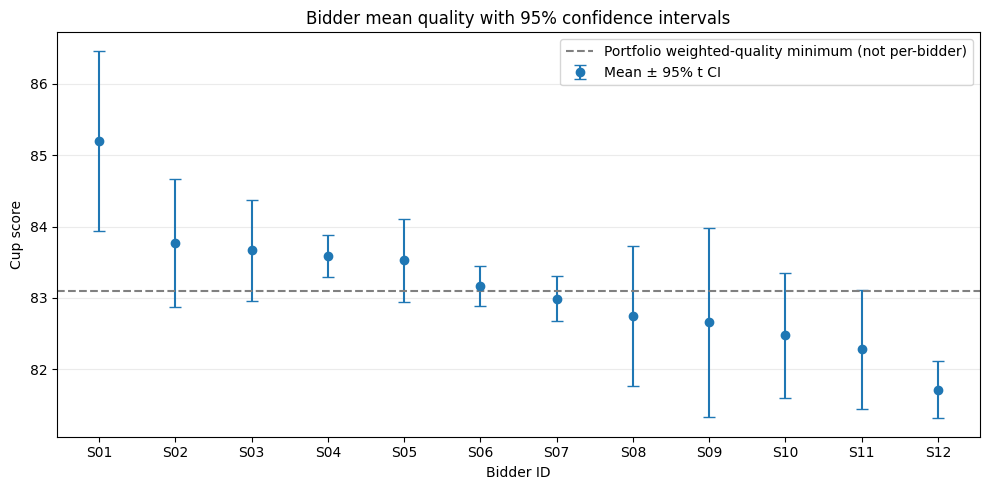

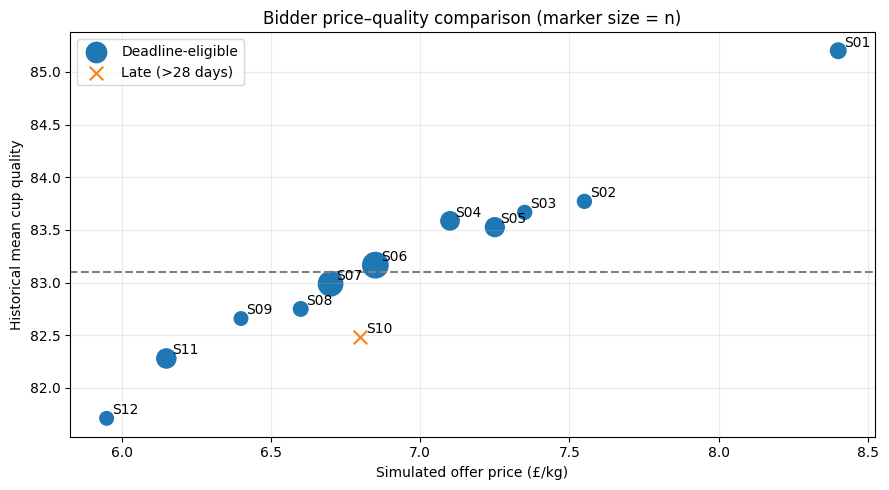


Part 1 finished: bidders table has 12 rows
All historical quality samples retained: 287
Missing processing methods: 57


In [30]:
# Read the supplied files and check for missing or inconsistent data
quality = pd.read_csv(
    DATA_DIR / REQUIRED_FILES[0],
    dtype={"sample_id": "string", "supplier_id": "string"},
)
offers = pd.read_csv(
    DATA_DIR / REQUIRED_FILES[1], dtype={"supplier_id": "string"}
)
scenarios = pd.read_csv(
    DATA_DIR / REQUIRED_FILES[2],
    dtype={"scenario": "string", "unavailable_supplier": "string"},
)
quality_samples = quality  # Existing group notebook compatibility.

required_columns = {
    "quality": {"sample_id", "supplier_id", "origin", "processing_method",
                "cup_points", "aroma", "flavour"},
    "offers": {"supplier_id", "fictional_name", "price_gbp_per_kg",
               "capacity_kg", "minimum_order_kg", "lead_time_days",
               "on_time_percent"},
    "scenarios": {"scenario", "demand_kg", "budget_gbp",
                  "minimum_weighted_quality", "deadline_days",
                  "maximum_supplier_share", "unavailable_supplier"},
}

for name, table in [("quality", quality), ("offers", offers),
                    ("scenarios", scenarios)]:
    missing_cols = required_columns[name] - set(table.columns)
    if missing_cols:
        raise ValueError(f"{name} is missing columns: {sorted(missing_cols)}")
    print(f"\n{name.upper()} — {table.shape[0]} rows, {table.shape[1]} columns")
    print("Missing by column:\n", table.isna().sum().to_string())
    print("Exact duplicate rows:", int(table.duplicated().sum()))

assert quality["sample_id"].notna().all() and quality["sample_id"].is_unique
assert quality["supplier_id"].notna().all()
assert quality["origin"].notna().all()
assert offers["supplier_id"].notna().all() and offers["supplier_id"].is_unique
assert scenarios["scenario"].notna().all() and scenarios["scenario"].is_unique
assert not quality.duplicated().any()
assert not offers.duplicated().any()
assert set(quality["supplier_id"]) == set(offers["supplier_id"])
assert set(scenarios["scenario"]) == {"Base", "Demand increase", "S01 unavailable"}
assert set(scenarios["unavailable_supplier"].dropna().astype(str)) <= set(offers["supplier_id"]) | {"None"}

# Audit numeric fields, without deleting historical samples.
for col, lower, upper in [("cup_points", 0, 100),
                          ("aroma", 0, 10), ("flavour", 0, 10)]:
    values = pd.to_numeric(quality[col], errors="coerce")
    assert values.notna().all(), f"Non-numeric/missing values in {col}"
    assert np.isfinite(values.to_numpy(dtype=float)).all(), col
    assert values.between(lower, upper).all(), f"Out-of-range {col}"
    if col == "cup_points":
        assert values.gt(0).all(), "Source requires positive cup scores"
    print(f"{col} range: {values.min():.2f} – {values.max():.2f}")

# processing_method is descriptive, not part of the required quality score.
missing_processing = (
    quality["processing_method"].isna()
    | quality["processing_method"].astype("string").str.strip().eq("").fillna(False)
)
print("Missing/blank processing methods:", int(missing_processing.sum()))

# Validate simulated numeric restrictions before relying on them.
offer_numbers = ["price_gbp_per_kg", "capacity_kg", "minimum_order_kg",
                 "lead_time_days", "on_time_percent"]
scenario_numbers = ["demand_kg", "budget_gbp", "minimum_weighted_quality",
                    "deadline_days", "maximum_supplier_share"]
assert offers[offer_numbers].notna().all().all()
assert scenarios[scenario_numbers].notna().all().all()
assert offers["price_gbp_per_kg"].gt(0).all()
assert offers["capacity_kg"].gt(0).all()
assert offers["minimum_order_kg"].ge(0).all()
assert offers["minimum_order_kg"].le(offers["capacity_kg"]).all()
assert offers["lead_time_days"].ge(0).all()
assert offers["on_time_percent"].between(0, 100).all()
assert scenarios["demand_kg"].gt(0).all()
assert scenarios["budget_gbp"].gt(0).all()
assert scenarios["deadline_days"].gt(0).all()
assert scenarios["minimum_weighted_quality"].between(0, 100).all()
assert scenarios["maximum_supplier_share"].between(0, 1).all()
assert (offers[["capacity_kg", "minimum_order_kg", "lead_time_days"]] % 1 == 0).all().all()
assert (scenarios[["demand_kg", "deadline_days"]] % 1 == 0).all().all()

# Summarise the historical quality scores by supplier
origin_per_bidder = quality.groupby("supplier_id")["origin"].nunique(dropna=False)
assert origin_per_bidder.eq(1).all(), "A bidder has multiple origin labels"

quality_tagged = quality.assign(processing_missing=missing_processing.astype(int))
quality_summary = (
    quality_tagged.groupby("supplier_id", as_index=False)
    .agg(
        n=("cup_points", "count"),
        mean_quality=("cup_points", "mean"),
        sd_quality=("cup_points", "std"),  # Sample SD (ddof=1).
        origin=("origin", "first"),
        missing_processing=("processing_missing", "sum"),
        mean_aroma=("aroma", "mean"),
        mean_flavour=("flavour", "mean"),
    )
)
assert quality_summary["n"].ge(2).all(), "t CI requires n >= 2"
assert quality_summary["n"].sum() == len(quality)

# Two-sided 95% Student-t confidence interval for each bidder mean.
quality_summary["se_quality"] = (
    quality_summary["sd_quality"] / np.sqrt(quality_summary["n"])
)
quality_summary["t_critical"] = t.ppf(0.975, quality_summary["n"] - 1)
quality_summary["ci95_margin"] = (
    quality_summary["t_critical"] * quality_summary["se_quality"]
)
quality_summary["ci95_low"] = (
    quality_summary["mean_quality"] - quality_summary["ci95_margin"]
)
quality_summary["ci95_high"] = (
    quality_summary["mean_quality"] + quality_summary["ci95_margin"]
)

# Weighted reconciliation: groups must reconstruct the original overall mean.
weighted_overall = (
    (quality_summary["n"] * quality_summary["mean_quality"]).sum()
    / quality_summary["n"].sum()
)
assert np.isclose(weighted_overall, quality["cup_points"].mean())

# Display the supplier-level quality statistics calculated above.
display(
    quality_summary[[
        "supplier_id", "n", "mean_quality", "sd_quality",
        "ci95_low", "ci95_high"
    ]].round(3)
)

# Add the supplier offers and check delivery eligibility
bidders = offers.merge(
    quality_summary, on="supplier_id", how="left",
    validate="one_to_one", indicator=True,
)
print("\nMerge results:\n", bidders["_merge"].value_counts().to_string())
assert len(bidders) == len(offers)
assert bidders["_merge"].eq("both").all()
bidders = bidders.drop(columns="_merge")

base_scen = scenarios.loc[scenarios["scenario"].eq("Base")].iloc[0]
bidders["eligible"] = bidders["lead_time_days"].le(
    int(base_scen["deadline_days"])
)
print("\nSupplier data for other group sections:")
print(bidders[["supplier_id", "n", "mean_quality", "sd_quality",
               "ci95_low", "ci95_high", "price_gbp_per_kg", "capacity_kg",
               "minimum_order_kg", "lead_time_days", "eligible"]]
      .sort_values("supplier_id").round(3).to_string(index=False))

# Plot the quality estimates and compare price against quality
ordered = bidders.sort_values("mean_quality", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
x_positions = np.arange(len(ordered))
ax.errorbar(
    x_positions, ordered["mean_quality"],
    yerr=ordered["ci95_margin"], fmt="o", capsize=4,
    label="Mean ± 95% t CI",
)
quality_floor = float(base_scen["minimum_weighted_quality"])
ax.axhline(quality_floor, color="gray", linestyle="--",
           label="Portfolio weighted-quality minimum (not per-bidder)")
ax.set_xticks(x_positions, ordered["supplier_id"])
ax.set_xlabel("Bidder ID")
ax.set_ylabel("Cup score")
ax.set_title("Bidder mean quality with 95% confidence intervals")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for eligibility, marker in [(True, "o"), (False, "x")]:
    group = bidders.loc[bidders["eligible"].eq(eligibility)]
    ax.scatter(
        group["price_gbp_per_kg"], group["mean_quality"],
        s=40 + group["n"] * 5, marker=marker,
        label="Deadline-eligible" if eligibility else "Late (>28 days)",
    )
for row in bidders.itertuples():
    ax.annotate(row.supplier_id,
                (row.price_gbp_per_kg, row.mean_quality),
                xytext=(4, 3), textcoords="offset points")
ax.axhline(quality_floor, color="gray", linestyle="--")
ax.set_xlabel("Simulated offer price (£/kg)")
ax.set_ylabel("Historical mean cup quality")
ax.set_title("Bidder price–quality comparison (marker size = n)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

OUTPUT_DIR.mkdir(exist_ok=True)
bidders.to_csv(OUTPUT_DIR / "bidders_quality_summary.csv", index=False)
print("\nPart 1 finished: bidders table has", len(bidders), "rows")
print("All historical quality samples retained:", len(quality))
print("Missing processing methods:", int(missing_processing.sum()))

# Section 2

**Baseline and Checker**

Name: Kim

### Description

Write the shared check_plan() function first

Lowest-price-first baseline for all 3 scenarios

Report which rules each baseline passes or fails


##### Check Plan Function

In [31]:
# Check whether an order plan meets the scenario requirements
# plan: quantity ordered from each supplier (including 0 kg orders)
# scen: demand, budget and other requirements for one scenario
def check_plan(plan, scen):
    supplier_ids = pd.Index(bidders["supplier_id"])

    # The plan must include all 12 suppliers exactly once
    if not isinstance(plan, pd.Series):
        raise ValueError("plan must be a pandas Series")
    if len(plan) != len(supplier_ids) or set(plan.index) != set(supplier_ids):
        raise ValueError("plan must include all supplier IDs")

    q = pd.to_numeric(plan.reindex(supplier_ids), errors="coerce")
    if q.isna().any() or not np.isfinite(q).all():
        raise ValueError("Invalid order quantities")

    # Match order quantities with supplier prices, quality and capacity
    b = bidders.set_index("supplier_id").loc[supplier_ids]

    demand = int(scen["demand_kg"])
    budget = float(scen["budget_gbp"])
    quality_min = float(scen["minimum_weighted_quality"])
    deadline = int(scen["deadline_days"])
    share_limit = float(scen["maximum_supplier_share"])
    unavailable = scen["unavailable_supplier"]

    if pd.isna(unavailable) or str(unavailable).strip().lower() == "none":
        unavailable = None

    # Calculate the cost and quality of the order plan
    used = q > 0
    total_kg = q.sum()
    cost = (q * b["price_gbp_per_kg"]).sum()

    if total_kg > 0:
        weighted_quality = (q * b["mean_quality"]).sum() / total_kg
        on_time_index = (q * b["on_time_percent"]).sum() / total_kg
    else:
        weighted_quality = float("nan")
        on_time_index = float("nan")

    # Check all ten conditions. Unused suppliers (0 kg) are allowed.
    checks = {
        "Nonnegative quantities": bool((q >= 0).all()),
        "Whole kilograms": bool((q % 1 == 0).all()),
        "Exact demand": bool(total_kg == demand),
        "Zero or minimum order": bool(((~used) | (q >= b["minimum_order_kg"])).all()),
        "Within supplier capacity": bool((q <= b["capacity_kg"]).all()),
        "Max supplier share": bool((q <= share_limit * demand).all()),
        "Delivery deadline": bool(((~used) | (b["lead_time_days"] <= deadline)).all()),
        "Unavailable supplier": bool(unavailable is None or q.loc[unavailable] == 0),
        "Within budget": bool(round(cost, 2) <= budget),
        "Weighted quality": bool(weighted_quality >= quality_min),
    }

    # Keep the numerical results separate from the pass/fail checks
    metrics = {
        "scenario": str(scen["scenario"]),
        "ordered_kg": float(total_kg),
        "demand_kg": demand,
        "total_cost_gbp": float(cost),
        "weighted_quality": float(weighted_quality),
        "quality_margin": float(weighted_quality - quality_min),
        "unused_budget_gbp": float(budget - cost),
        "maximum_supplier_share": float(q.max() / demand),
        "used_bidders": int(used.sum()),
        "weighted_on_time_index_pct": float(on_time_index),
        "feasible": all(checks.values()),
    }
    return metrics, checks

##### Lowest Price Function

In [32]:
# Build a price-first order plan, starting with minimum orders
# This is a simple baseline, not a cost or quality optimiser
def lowest_price_first(scen):
    demand = int(scen["demand_kg"])
    deadline = int(scen["deadline_days"])
    share_limit = int(float(scen["maximum_supplier_share"]) * demand)
    unavailable = scen["unavailable_supplier"]

    if pd.isna(unavailable) or str(unavailable).strip().lower() == "none":
        unavailable = None

    # Include all suppliers, even those with no order
    plan = pd.Series(0, index=bidders["supplier_id"], dtype=int, name="quantity_kg")
    candidates = bidders.sort_values(["price_gbp_per_kg", "supplier_id"])

    selected = []
    total_capacity = 0

    # Select enough eligible suppliers, starting with the cheapest
    for row in candidates.itertuples(index=False):
        if row.lead_time_days > deadline or row.supplier_id == unavailable:
            continue

        maximum = min(int(row.capacity_kg), share_limit)
        if maximum < row.minimum_order_kg:
            continue

        selected.append(row)
        total_capacity += maximum
        if total_capacity >= demand:
            break

    if total_capacity < demand:
        raise ValueError("Not enough supplier capacity")

    minimum_total = sum(row.minimum_order_kg for row in selected)
    if minimum_total > demand:
        raise ValueError("Minimum orders exceed demand")

    # Assign minimum orders first, avoiding a small leftover order
    for row in selected:
        plan.loc[row.supplier_id] = int(row.minimum_order_kg)

    remaining = demand - int(plan.sum())

    # Give the remaining demand to the cheapest suppliers first
    for row in selected:
        maximum = min(int(row.capacity_kg), share_limit)
        available = maximum - plan.loc[row.supplier_id]
        quantity = min(remaining, available)

        plan.loc[row.supplier_id] += quantity
        remaining -= quantity
        if remaining == 0:
            break

    return plan

##### Baseline Main

In [33]:
# Run the baseline and check every scenario
baseline_plans = {}
baseline_checks = {}
results = []
allocation_rows = []

for i in range(len(scenarios)):
    scen = scenarios.iloc[i]
    name = scen["scenario"]

    plan = lowest_price_first(scen)
    metrics, checks = check_plan(plan, scen)

    baseline_plans[name] = plan
    baseline_checks[name] = checks

    # Show which conditions are not met
    failed = []
    for rule in checks:
        if checks[rule] == False:
            failed.append(rule)
    metrics["failed_checks"] = ", ".join(failed) if failed else "None"
    results.append(metrics)

    # Save all 12 suppliers, including 0 kg orders
    for supplier_id, quantity in plan.items():
        allocation_rows.append({
            "scenario": name,
            "supplier_id": supplier_id,
            "quantity_kg": int(quantity),
        })


# Make tables for the three scenarios
baseline_summary = pd.DataFrame(results)
baseline_allocations = pd.DataFrame(allocation_rows)
allocation_table = pd.DataFrame(baseline_plans)
checks_table = pd.DataFrame(baseline_checks)

assert len(baseline_allocations) == len(scenarios) * len(bidders)
assert not baseline_allocations.duplicated(["scenario", "supplier_id"]).any()

print("=== BASELINE SUMMARY ===")
display(baseline_summary[[
    "scenario", "ordered_kg", "total_cost_gbp", "weighted_quality",
    "unused_budget_gbp", "feasible", "failed_checks"
]].round(4))

print("\n=== ORDER ALLOCATION (kg) ===")
display(allocation_table)

print("\n=== CONSTRAINT CHECKS ===")
display(checks_table.replace({True: "PASS", False: "FAIL"}))

# These are baseline results, not the final sourcing decisions
baseline_summary.to_csv(OUTPUT_DIR / "baseline_summary.csv", index=False)
baseline_allocations.to_csv(
    OUTPUT_DIR / "baseline_allocations_NOT_FINAL.csv", index=False
)

=== BASELINE SUMMARY ===


,scenario,ordered_kg,total_cost_gbp,weighted_quality,unused_budget_gbp,feasible,failed_checks
0,Base,3000.0,18410.0,82.1538,5590.0,False,Weighted quality
1,Demand increase,3600.0,22142.0,82.1749,6658.0,False,Weighted quality
2,S01 unavailable,3000.0,18410.0,82.1538,5590.0,False,Weighted quality



=== ORDER ALLOCATION (kg) ===


,Base,Demand increase,S01 unavailable
supplier_id,,,
S01,0,0,0
S02,0,0,0
S03,0,0,0
S04,0,0,0
S05,0,0,0
S06,0,0,0
S07,0,0,0
S08,0,0,0
S09,800,1160,800



=== CONSTRAINT CHECKS ===


,Base,Demand increase,S01 unavailable
Nonnegative quantities,PASS,PASS,PASS
Whole kilograms,PASS,PASS,PASS
Exact demand,PASS,PASS,PASS
Zero or minimum order,PASS,PASS,PASS
Within supplier capacity,PASS,PASS,PASS
Max supplier share,PASS,PASS,PASS
Delivery deadline,PASS,PASS,PASS
Unavailable supplier,PASS,PASS,PASS
Within budget,PASS,PASS,PASS
Weighted quality,FAIL,FAIL,FAIL


# Section 3

**Optimisation**

Name: Joe Gibbon

### Description

Integer program (PuLP) with a binary 'used' variable for the 100 kg minimum

Solve all 3 scenarios; verify each with check_plan()

Export sourcing_decisions.csv (36 rows)

#### Checks and Set up

In [34]:
# With gapRel=0, GapLimit means the gap reached zero, i.e. proven optimal.
# (This CBC build reports it as GapLimit rather than Optimal.)
OK_STATUSES = {pulp.LpSolveStatus.Optimal, pulp.LpSolveStatus.GapLimit}
QUALITY_MARGIN = 1e-6


# Dicts for the optimisation model
ids = bidders["supplier_id"].tolist()
price = dict(zip(bidders["supplier_id"], bidders["price_gbp_per_kg"]))
capacity = dict(zip(bidders["supplier_id"], bidders["capacity_kg"]))
min_order = dict(zip(bidders["supplier_id"], bidders["minimum_order_kg"]))
lead_time = dict(zip(bidders["supplier_id"], bidders["lead_time_days"]))
quality = dict(zip(bidders["supplier_id"], bidders["mean_quality"]))

#### Base Model

In [37]:
def optimise_scenario(scen):

    # Retrieve requirements for the scenario
    demand = int(scen["demand_kg"])
    budget = float(scen["budget_gbp"])
    min_quality = float(scen["minimum_weighted_quality"])
    deadline = int(scen["deadline_days"])
    share_limit = float(scen["maximum_supplier_share"])
    unavailable = scen["unavailable_supplier"]
    if pd.isna(unavailable) or str(unavailable).strip().lower() == "none":
        unavailable = None


    # Which supplier are allowed in the model (checking both their availability and lead time)
    allowed_sup = {i: (lead_time[i] <= deadline and i != unavailable) for i in ids}
    max_kg = {i: min(capacity[i], int(share_limit * demand)) for i in ids}


    # Creates the model
    model = pulp.LpProblem("Coffee_Sourcing_Problem", pulp.LpMinimize)
    x = model.add_variable_dicts("kg", ids, lowBound=0, cat="Integer")
    y = model.add_variable_dicts("used", ids, lowBound=0, upBound=1, cat="Binary")

    model += pulp.lpSum([price[i] * x[i] for i in ids])
    model += pulp.lpSum([x[i] for i in ids]) == demand, "Demand"
    model += pulp.lpSum([price[i] * x[i] for i in ids]) <= budget, "Budget"


    # This constraint ensures that the weighted quality of the order meets the minimum requirement
    # An important thing to explain in the presentation (it changes how the model sees the quality, changing it from purely cost-centric)
    model += pulp.lpSum((quality[i] - min_quality - QUALITY_MARGIN) * x[i] for i in ids) >= 0, "Quality"


    # Loop to add the minimum orders, maximum orders and disallowed suppliers
    for i in ids:
        model += x[i] >= min_order[i] * y[i], f"Min_{i}"
        model += x[i] <= max_kg[i] * y[i], f"Max_{i}"
        if not allowed_sup[i]:
            model += y[i] == 0, f"NotAllowed_{i}"


    stats = model.solve(solver)

    if stats.status not in OK_STATUSES:
        raise RuntimeError(f"No proven optimal plan: {stats.status_str}")

    # Builds a pandas series
    plan = pd.Series({i: int(round(x[i].value())) for i in ids}, name="quantity_kg")
    plan.index.name = "supplier_id"

    return plan, stats.status_str


def build_plan_table(plan):

    plan_table = plan.reset_index()
    plan_table.columns = ["Supplier ID", "Quantity (kg)"]

    return plan_table
    
opt_plans = {}
opt_results = []

for s in scenarios["scenario"]:
    scen = scenarios.loc[scenarios["scenario"].eq(str(s))].iloc[0]
    plan, status = optimise_scenario(scen)
    metrics, checks = check_plan(plan, scen)

    print(s)
    print(status)
    print("Feasible:", metrics["feasible"])
    print("Cost:", metrics["total_cost_gbp"])
    display(build_plan_table(plan))

    opt_plans[s] = plan
    opt_results.append(metrics)


# Summary of the optimised plans (one row per scenario)
opt_summary = pd.DataFrame(opt_results)

assert len(opt_summary) == len(scenarios), "Expected one row per scenario"
assert opt_summary["feasible"].all(), "An optimised plan fails a rule - check before exporting"

print("=== OPTIMISED SUMMARY ===")
display(opt_summary[[
    "scenario", "ordered_kg", "total_cost_gbp", "weighted_quality",
    "quality_margin", "unused_budget_gbp", "used_bidders", "feasible"
]].round(4))

opt_summary.to_csv(OUTPUT_DIR / "optimised_summary.csv", index=False)



# Build the 36-row decisions table: every bidder in every scenario, zeros included
# Same pattern as Kim's allocation_rows in Section 2
decision_rows = []

for name, plan in opt_plans.items():
    for supplier_id, quantity in plan.items():
        decision_rows.append({
            "scenario": name,
            "supplier_id": supplier_id,
            "quantity_kg": int(quantity),
        })

decisions = pd.DataFrame(decision_rows)

# Save the final submission file
decisions_path = OUTPUT_DIR / "sourcing_decisions.csv"
decisions.to_csv(decisions_path, index=False)

# Reload the file and check it meets the brief
reloaded = pd.read_csv(decisions_path, dtype={"scenario": "string", "supplier_id": "string"})

assert len(reloaded) == len(scenarios) * len(bidders), "Expected 36 rows"
assert list(reloaded.columns) == ["scenario", "supplier_id", "quantity_kg"]
assert set(reloaded["scenario"]) == set(scenarios["scenario"]), "Scenario names must match exactly"
assert not reloaded.duplicated(["scenario", "supplier_id"]).any()

totals = reloaded.groupby("scenario")["quantity_kg"].sum()
demand_by_scen = scenarios.set_index("scenario")["demand_kg"]
assert (totals == demand_by_scen.loc[totals.index]).all(), "Totals must equal demand"

print("Saved:", decisions_path.resolve())
print("Rows:", len(reloaded))
display(totals.rename("Total kg"))


# Something to add!
# Create functions for each stage of the coding, note how adding more constaints can change the model and the results.

# Final task. Add on the comparisons and visualise them, this is something that will come across much better on the presentation.

# One last thing to add!
# A choice for which restriction to use from the start.

Base
Optimal
Feasible: True
Cost: 20227.5


,Supplier ID,Quantity (kg)
0,S01,150
1,S02,0
2,S03,0
3,S04,1200
4,S05,0
5,S06,0
6,S07,0
7,S08,0
8,S09,1200
9,S10,0


Demand increase
Optimal
Feasible: True
Cost: 24296.75


,Supplier ID,Quantity (kg)
0,S01,319
1,S02,0
2,S03,0
3,S04,1200
4,S05,0
5,S06,0
6,S07,0
7,S08,0
8,S09,1196
9,S10,0


S01 unavailable
Optimal
Feasible: True
Cost: 20231.4


,Supplier ID,Quantity (kg)
0,S01,0
1,S02,0
2,S03,0
3,S04,1200
4,S05,0
5,S06,0
6,S07,638
7,S08,0
8,S09,1162
9,S10,0


=== OPTIMISED SUMMARY ===


,scenario,ordered_kg,total_cost_gbp,weighted_quality,quality_margin,unused_budget_gbp,used_bidders,feasible
0,Base,3000.0,20227.50,83.1,0.0,3772.50,4,True
1,Demand increase,3600.0,24296.75,83.1,0.0,4503.25,4,True
2,S01 unavailable,3000.0,20231.40,83.1,0.0,3768.60,3,True


Saved: C:\Users\gibbo\OneDrive - University of Reading\Documents\MM311\MM311 Group Project\Results\sourcing_decisions.csv
Rows: 36


scenario
Base               3000
Demand increase    3600
S01 unavailable    3000
Name: Total kg, dtype: int64

# Section 4

**Scenarios, Risk, and Reccomendations**

Name:

### Description

Compact three-scenario comparison table

Quality-margin robustness, e.g. lower CI bound or drop-one-bidder test

On-time performance and origin concentration

Recommendation; assemble slides

In [36]:
# This is the code for S4
